<a href="https://colab.research.google.com/github/Chilakalapudisharon/ML_LAB_2026-27/blob/main/Mini_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Loan Approval Prediction Using Machine Learning**


**Aim:** To predict whether a loan application will be Approved or Rejected based on applicant details using machine learning algorithms.

**Description:** Loan Approval Prediction is a machine learning project that analyzes applicant information such as income, credit score, loan amount, employment experience, and existing debt.

The system uses different machine learning algorithms to predict whether a person is eligible for a loan.


**Step 1: Import libraries**



In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from sklearn.metrics import accuracy_score, classification_report

**Step 2: Create the dataset**

In [ ]:
np.random.seed(42)

data = pd.DataFrame({
    'Income': np.random.randint(20000, 100000, 200),
    'Credit_Score': np.random.randint(300, 850, 200),
    'Loan_Amount': np.random.randint(10000, 500000, 200),
    'Employment_Years': np.random.randint(0, 30, 200),
    'Existing_Debt': np.random.randint(1000, 50000, 200)
})

# Generate loan approval status
data['Loan_Status'] = np.where(
    (data['Credit_Score'] > 600) &
    (data['Income'] > 35000) &
    (data['Existing_Debt'] < 35000),
    'Approved', 'Rejected'
)

# Convert output into numbers
data['Loan_Status'] = data['Loan_Status'].map({
    'Approved': 1,
    'Rejected': 0
})

print(data.head())
print("Dataset Shape:", data.shape)
print(data.isnull().sum())

   Income  Credit_Score  Loan_Amount  Employment_Years  Existing_Debt  \
0   35795           637        21338                15          34434   
1   20860           772       141484                 7           5188   
2   96820           450        17543                 5          11161   
3   74886           714       378035                11          29732   
4   26265           597       436712                23          12314   

   Loan_Status  
0            1  
1            0  
2            0  
3            1  
4            0  
Dataset Shape: (200, 6)
Income              0
Credit_Score        0
Loan_Amount         0
Employment_Years    0
Existing_Debt       0
Loan_Status         0
dtype: int64


Note: Actual values depend on the generated dataset.


**Step 3: Separate input and output**






In [ ]:
X = data.drop('Loan_Status', axis=1)
y = data['Loan_Status']

print("Input data:")
print(X.head())

print("Output data:")
print(y.head())

Input data:
   Income  Credit_Score  Loan_Amount  Employment_Years  Existing_Debt
0   35795           637        21338                15          34434
1   20860           772       141484                 7           5188
2   96820           450        17543                 5          11161
3   74886           714       378035                11          29732
4   26265           597       436712                23          12314
Output data:
0    1
1    0
2    0
3    1
4    0
Name: Loan_Status, dtype: int64


**Step 4: Split training and testing data**

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (160, 5)
Testing data: (40, 5)


**Step 5: Apply machine learning algorithms**

In [ ]:
models = {
    'KNN': make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5)
    ),

    'Decision Tree': DecisionTreeClassifier(
        random_state=42
    ),

    'Logistic Regression': make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000)
    ),

    'Random Forest': RandomForestClassifier(
        random_state=42
    ),

    'SVM': make_pipeline(
        StandardScaler(),
        SVC()
    )
}

results = {}

for name, model in models.items():

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)

    results[name] = accuracy

    print(name, "Accuracy:",
          round(accuracy * 100, 2), "%")

KNN Accuracy: 92.5 %
Decision Tree Accuracy: 95.0 %
Logistic Regression Accuracy: 92.5 %
Random Forest Accuracy: 95.0 %
SVM Accuracy: 92.5 %


**Step 6: Compare model accuracy**

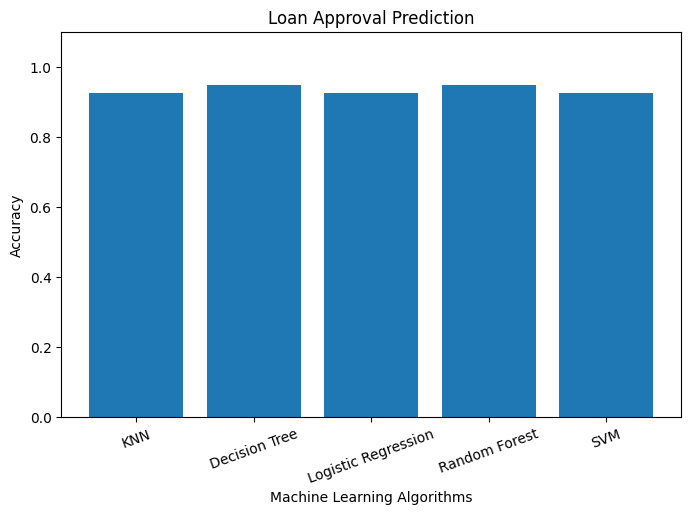

In [ ]:
plt.figure(figsize=(8, 5))

plt.bar(results.keys(), results.values())

plt.xlabel("Machine Learning Algorithms")
plt.ylabel("Accuracy")

plt.title("Loan Approval Prediction")

plt.ylim(0, 1.1)

plt.xticks(rotation=20)

plt.show()

**Step 7: Classification report**

In [ ]:
# Select best model
best_name = max(results, key=results.get)

best_model = models[best_name]

y_pred = best_model.predict(X_test)

print("Best Algorithm:", best_name)

print("\nClassification Report:")

print(classification_report(
    y_test,
    y_pred,
    target_names=['Rejected', 'Approved']
))

Best Algorithm: Decision Tree

Classification Report:
              precision    recall  f1-score   support

    Rejected       0.94      1.00      0.97        31
    Approved       1.00      0.78      0.88         9

    accuracy                           0.95        40
   macro avg       0.97      0.89      0.92        40
weighted avg       0.95      0.95      0.95        40



**Step 8: Predict a new applicant's loan status**

In [ ]:
new_applicant = pd.DataFrame({
    'Income': [75000],
    'Credit_Score': [750],
    'Loan_Amount': [200000],
    'Employment_Years': [8],
    'Existing_Debt': [10000]
})

prediction = best_model.predict(new_applicant)

if prediction[0] == 1:
    print("Predicted Loan Status: Approved")
else:
    print("Predicted Loan Status: Rejected")

Predicted Loan Status: Approved


**Conclusion:**
The Loan Approval Prediction System uses machine learning algorithms to predict whether a loan application will be approved or rejected. Different algorithms are compared based on their accuracy. The system helps financial institutions analyze applicant details and make faster loan decisions.